# ♟️ Chess Numba — 新舊引擎錦標賽對戰 (Colab Tournament Runner)

本 Notebook 用於在 Google Colab 雲端高並行 CPU 環境下，讓 **新版本引擎 (Candidate / New)** 與 **基準版本引擎 (Baseline / Old)** 進行成對換先（Color-swapped Pairs）錦標賽對抗：

### 🎯 本輪對抗設定 (實驗 E85：SEE 子力價值統一 MG_MATERIAL_VALUES + 門檻等比例縮放與 SPSA 納入)
* **Engine 1 (New / Candidate)**: `chess_engine/classical`
  * ✅ **SEE 子力價值統一**：`SEE_PIECE_VALUES` 直接引用 `MG_MATERIAL_VALUES` (`[100, 347, 364, 572, 1170, 20000]`)，消除 ProbCut SEE 過濾器、Capture LMR 與評估尺度的落差。
  * ✅ **SEE 相關門檻與歷史斜率等比例縮放 ($	imes 1.134$)**：
    1. `PRUNING_CAPTURE_SEE_MARGIN`: `-102` $\to$ **`-116`** (Slot `TUNE_SEE_CAP_MARGIN = 4`)
    2. `PRUNING_QUIET_SEE_MARGIN`: `-32` $\to$ **`-36`** (Slot `TUNE_SEE_QUIET_MARGIN = 5`)
    3. `QS_SEE_THRESHOLD`: `-80` $\to$ **`-91`** (Slot `TUNE_QS_SEE = 14`)
    4. `CHECK_SEE_THRESHOLD`: `-75` $\to$ **`-85`** (Slot `TUNE_CHECK_SEE_THR = 42`)
    5. `CAP_SEE_CAPTHIST_NUM`: `34` $\to$ **`39`** (Slot `TUNE_CAP_SEE_HIST_NUM = 43`)
  * ✅ **Runtime SPSA 完整納入**：`SearchContext.tune` 擴充至 44 槽，熱路徑改讀動態參數，並提供專屬 `--profile see`。
* **Engine 2 (Old / Baseline)**: `chess_engine/classical_old`（E84 採納基線，包含 SEE 核心漏洞修復與前置合法性過濾，但維持舊獨立 `SEE_PIECE_VALUES = [100, 320, 330, 500, 900, 20000]` 與舊版門檻）
* **時控模式**: 固定節點（400,000 nodes 長時控）
* **對戰規格**: 600 局（300 對開局交換白黑），64MB 轉置表，開局庫 `data/openings.epd`
* **統計模型**: SPRT（Sequential Probability Ratio Test）與 Elo 95% 置信區間


In [5]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.4Gi        45Gi       2.2Mi       4.8Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.18


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [6]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content/chess_numba
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 16 (delta 13), reused 16 (delta 13), pack-reused 0 (from 0)
Unpacking objects: 100% (16/16), 31.31 KiB | 1.65 MiB/s, done.
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
   cec2033..34a7ef0  feat-initial-bitboard-setup -> origin/feat-initial-bitboard-setup
Already on 'feat-initial-bitboard-setup'
Your branch is behind 'origin/feat-initial-bitboard-setup' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
HEAD is now at 34a7ef0 BUG-4：EG_SAFETY_SCALE 實質死碼與 SearchContext.eval_weights 脫鉤修復

🎉 環境與相依套件安裝完畢！


In [7]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff-code

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in evaluation.py:
--- classical_old/evaluation.py
+++ classical/evaluation.py
@@ -16,1775 +16,3556 @@
 )
 from chess_engine.classical.engine_types import (
     piece_bbs_signature, occupancy_bbs_signature, game_state_signature, piece_counts_signature
+
 )
+
 from chess_engine.classical.move_generator import (
+
     get_bishop_attacks, get_rook_attacks, get_queen_attacks, KNIGHT_ATTACKS, PAWN_ATTACKS, KING_ATTACKS,
+
     get_pinned_pieces
+
 )
+
 from chess_engine.classical.pawns import (
+
     NOT_A_FILE, NOT_H_FILE, CENTER_FILES, CHEBYSHEV_DISTANCE, MANHATTAN_DISTANCE,
+
     WHITE_PASSED_PAWN_MASKS, BLACK_PASSED_PAWN_MASKS,
+
     WHITE_FORWARD_FILE_MASKS, BLACK_FORWARD_FILE_MASKS,
+
     WHITE_FORWARD_RANKS, BLACK_FORWARD_RANKS,
+
     ADJACENT_FILES_MASKS, PHALANX_MASK, WHITE_SUPPORT_MASK, BLACK_SUPPORT_MASK,
+
     evaluate_pawn_structure, evaluate_pawn_structure_cached,
+

In [8]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 1000                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 400000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB} --seed 31415926


♟️ 錦標賽參數配置：
  總局數: 1000 局 (500 對成對換先開局)  時控: 400,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=31415926
Adjudication: win >= 500 cp (10 plies), draw <= 8 cp (12 plies after move 40)
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 1 nodes 501 nps 1197 hashfull 0.0% time 418 pv e2a6
info depth 2 score cp 1 nodes 916 nps 1985 hashfull 0.0% time 461 pv e2a6 b4c3
info depth 3 score cp -34 nodes 1934 nps 4181 hashfull 0.0% time 462 pv e2a6 b4c3 d2c3
info depth 4 score cp -34 nodes 2338 nps 5047 hashfull 0.0% time 463 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -125 nodes 7197 nps 15344 hashfull 0.0% time 469 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


In [9]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

# report_path = Path("tournament_analysis/game_stats_report.txt")
# if report_path.exists():
#     print("\n" + "=" * 60)
#     print("📊 對戰統計結果報告 (Game Stats Report)：")
#     print("=" * 60)
#     print(report_path.read_text(encoding='utf-8'))

# search_report_path = Path("tournament_analysis/search_stats_report.txt")
# if search_report_path.exists():
#     print("\n" + "=" * 60)
#     print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
#     print("=" * 60)
#     print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.10.31': 686}
White 名稱: Counter({'New': 343, 'Old': 343})
Black 名稱: Counter({'Old': 343, 'New': 343})

[1. 總體戰績與 Elo 表現]
總對局數 : 686 局
戰績統計 : 勝 165 | 和 408 | 負 113
勝率(含和) : 53.79%
和局率 : 59.48%
相對 Elo 變化 : 26.39
95% 信賴區間 : [9.64, 43.26]
CI 單位 : color-swapped pair clustered (n=343 independent units)
  ✅ 95% 信心：明顯強於對手（CI 下界 > 0）


[2. 先手優勢與執色分析]
持白勝率 : 58.75% (勝:106 和:191 負:46)
持黑勝率 : 48.83% (勝:59 和:217 負:67)
賽局總體白方勝率 : 54.96%
卡方 p-value : 7.6847e-05


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - Nc3: n=12 勝率 54.17% (W3 D7 L2)
  - h3: n=11 勝率 77.27% (W6 D5 L0)
  - cxd5: n=9 勝率 77.78% (W5 D4 L0)
  - e3: n=9 勝率 61.11% (W3 D5 L1)
  - a3: n=9 勝率 55.56% (W4 D2 L3)
【持黑面對的主流開局】
  - 面對 h3: n=13 勝率


📈 累積分數曲線 (Cumulative Score)：


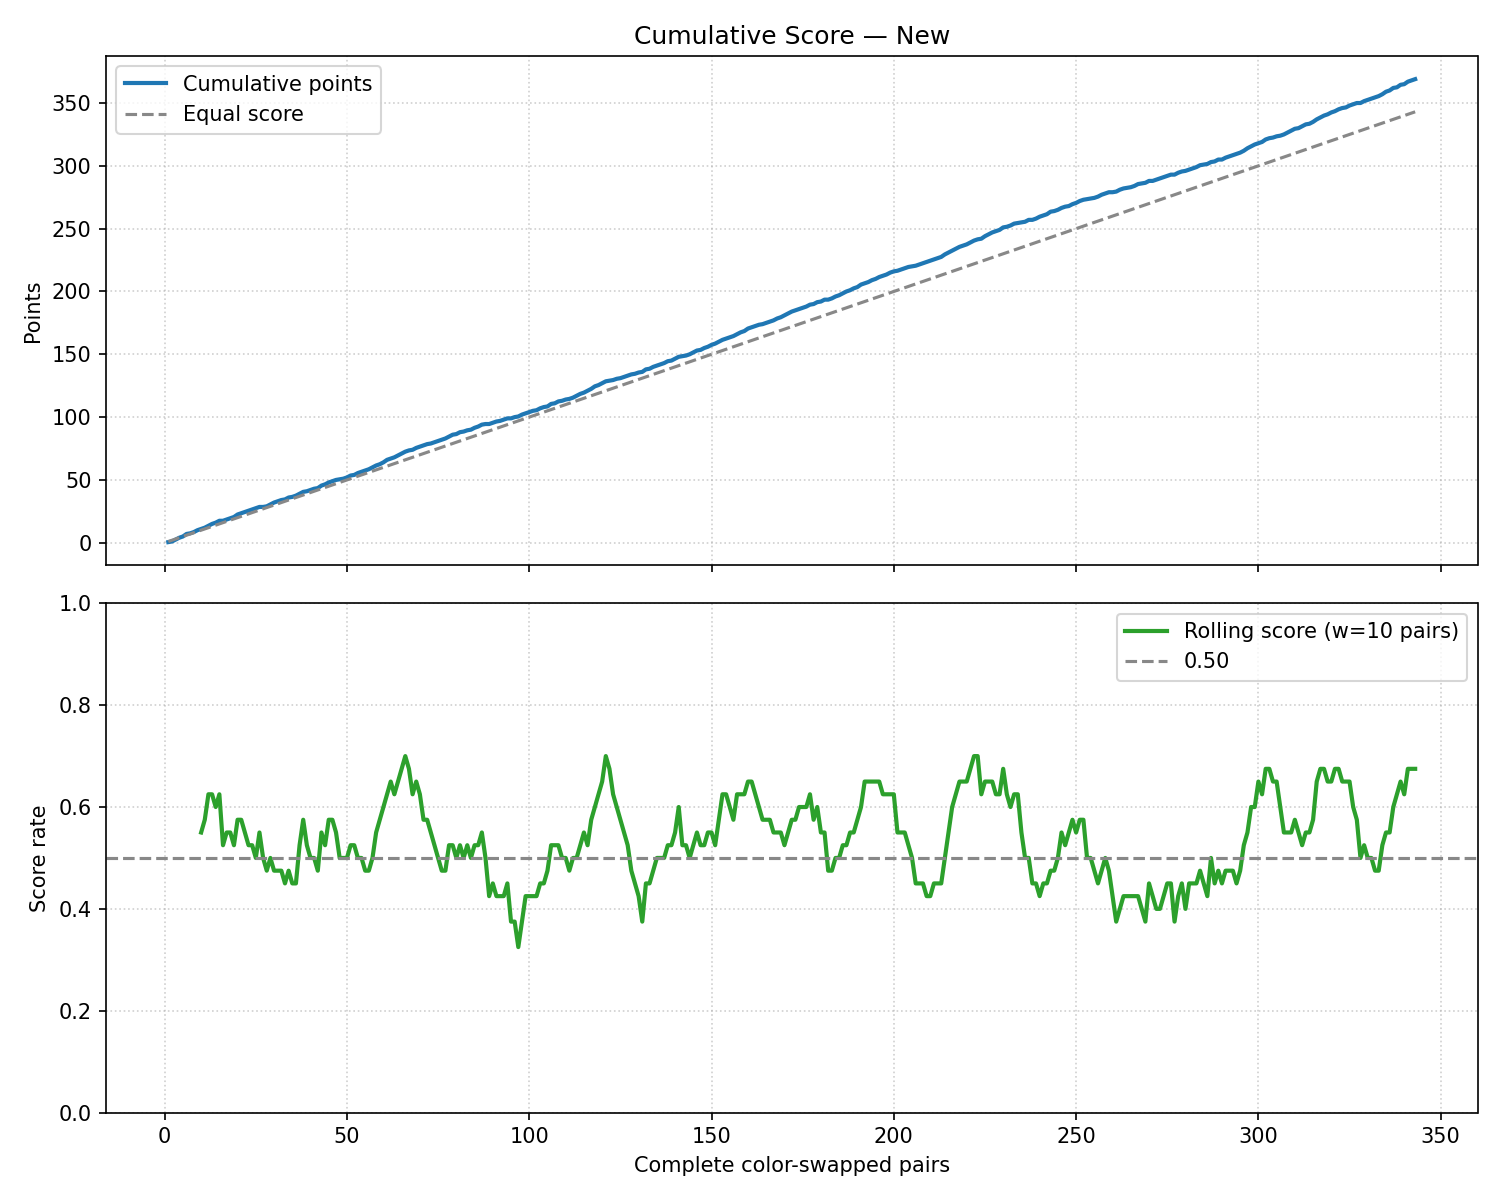


📈 Elo 置信區間收斂圖 (Elo CI)：


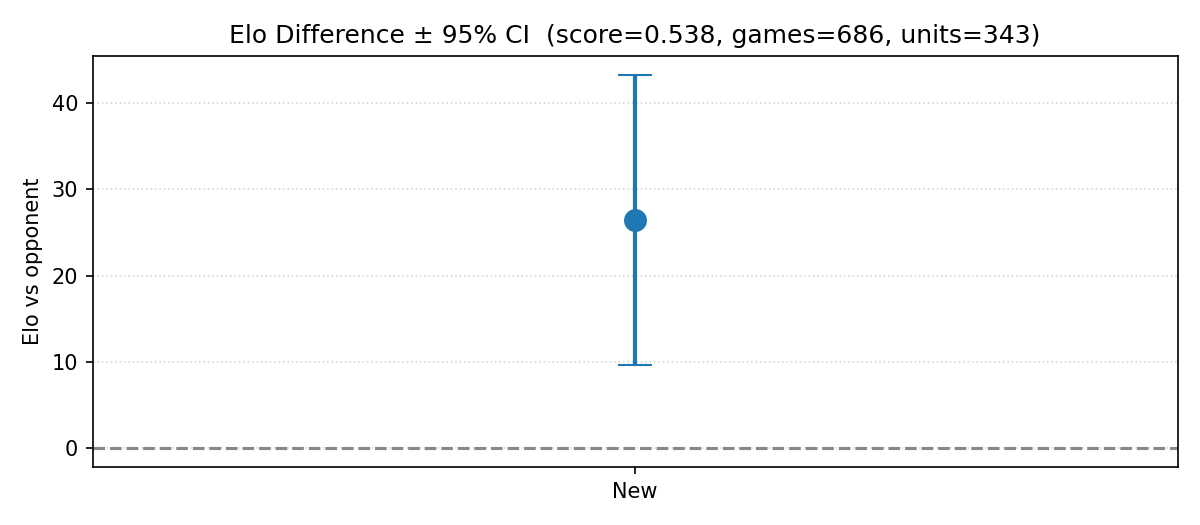


📈 每手搜尋深度 (Depth per Move)：


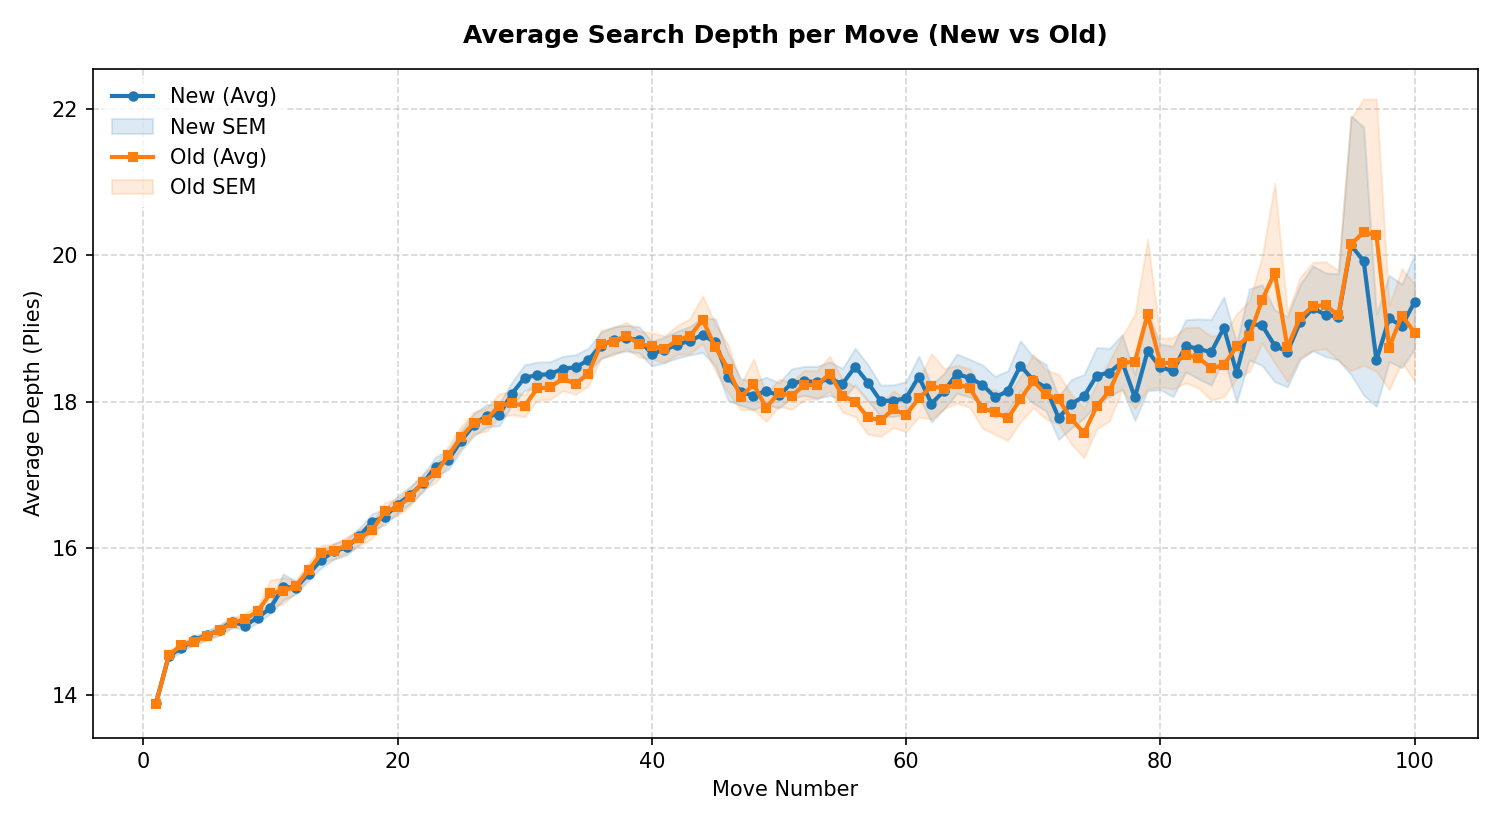


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


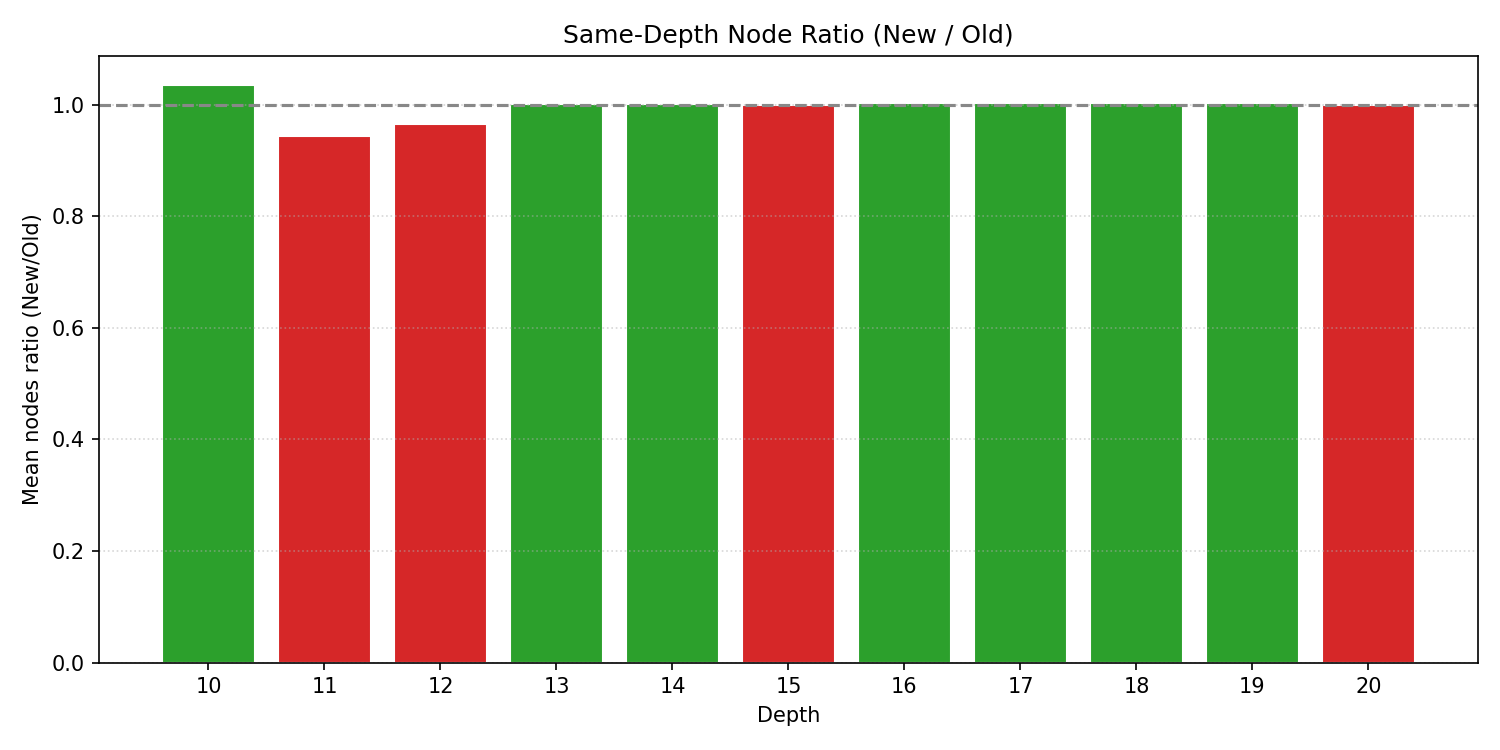


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


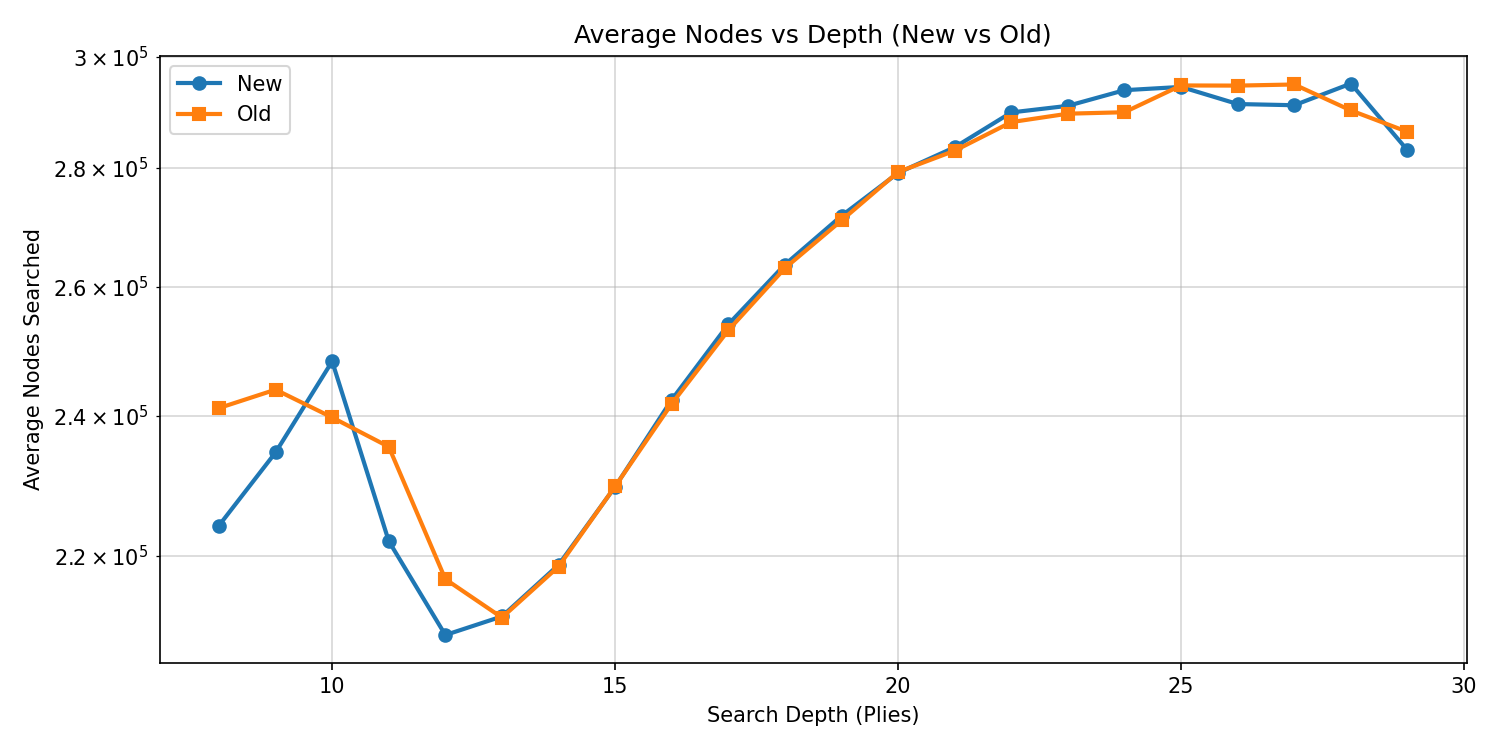


📈 黑白勝負分佈 (WDL by Color)：


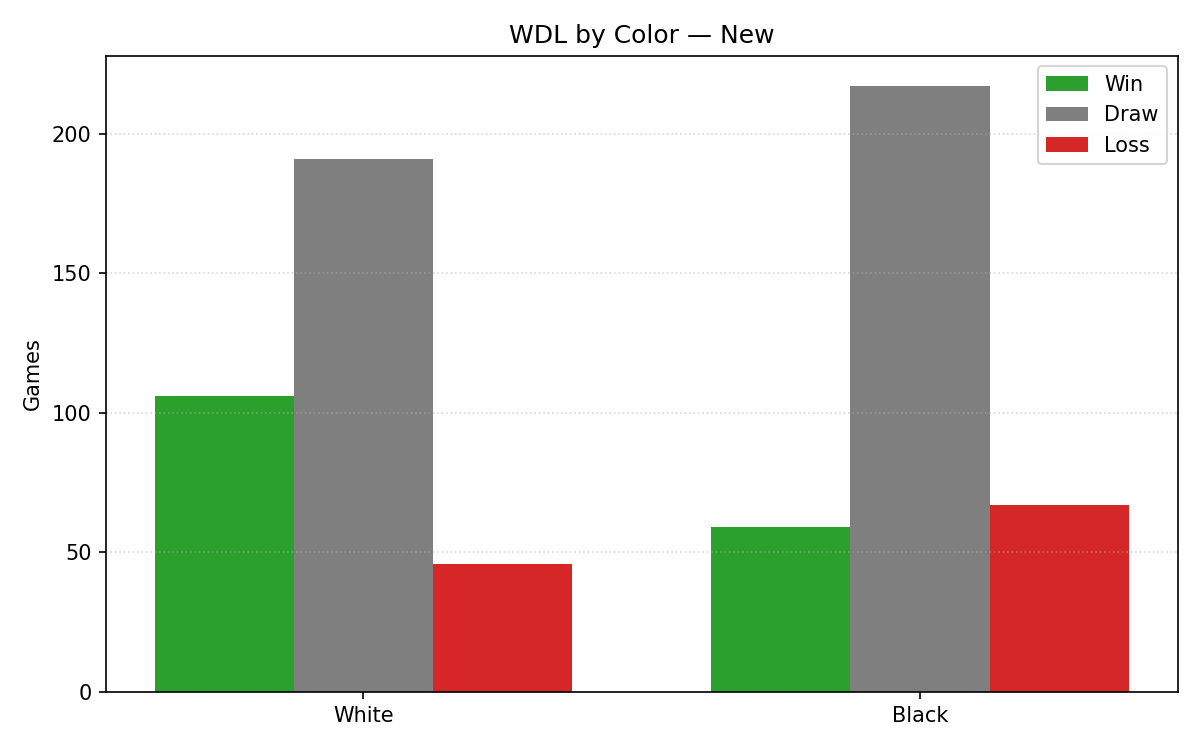

In [10]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [ ]:
# =====================================================================
# 步驟 7: 一鍵打包所有報告、圖表與 PGN 棋譜並下載
# =====================================================================
import datetime

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
zip_filename = f"tournament_results_{timestamp}.zip"

!zip -q {zip_filename} tournament_analysis/*.png tournament_analysis/*.txt tournament_analysis/tournament_results.pgn
print(f"📦 已打包完成: {zip_filename}")

try:
    from google.colab import files
    files.download(zip_filename)
    print("⬇️ 已觸發下載！")
except ImportError:
    print(f"💡 本地環境執行，壓縮包位於當前目錄: {zip_filename}")


In [11]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
